# Baseline Model Tuning: CatBoost
Follow-up to `03_baseline_model_testing.ipynb`, which compared 5 models with their starting settings. This notebook **tunes CatBoost**: it searches for better settings (hyperparameters) and chooses the Disrupted decision threshold.

**Why CatBoost:** in 03 it had the best Disrupted PR-AUC (it ranked Disrupted rows best) but a lower macro-F1, partly because the default rule flagged too many rows as Disrupted. Tuning and a chosen threshold could change that. It also ranked first among single tuned models in the TabArena benchmark from the literature review.

**How tuning is organized:** each algorithm is tuned in its own notebook (`03_2_baseline_model_tuning_lightgbm`, `03_2_baseline_model_tuning_random_forest`, `03_2_baseline_model_tuning_catboost`, `03_2_baseline_model_tuning_xgboost`, `03_2_baseline_model_tuning_logistic_regression`), and a later notebook compares them. To make the comparison fair, every tuning notebook uses the shared setup in `tuning_setup.py` (same training rows, same 5 folds, same scores, same threshold method) and saves its results in the same format to `results/tuning/<model>/`.

**The test set is still not used.** Only the final comparison notebook will score it, once.

Steps:
1. Load the training data and the shared setup
2. Score untuned CatBoost as the starting point
3. Define which settings to search, and over what ranges
4. Run a randomized search with stratified 5-fold cross-validation
5. Compare tuned vs. untuned, fold by fold
6. Choose the Disrupted threshold
7. Save the results

## 1. Load Data & Shared Setup
`tuning_setup.py` (in this folder) holds everything the tuning notebooks share:
- `load_training_data()`: the **training rows only** of `model_ready.csv`, with the target encoded as Normal = 0, Delayed = 1, Disrupted = 2 (same as 03)
- `make_folds()`: the **same 5 stratified folds as 03** (`shuffle=True, random_state=42`), so scores here can be compared directly with 03
- `score_predictions()` / `score_folds()`: the same scores as 03 (macro-F1, F1 per status, Disrupted precision/recall/PR-AUC, ROC-AUC)
- threshold helpers and `save_tuning_results()`, explained in sections 6 and 7

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict

from tuning_setup import (DISRUPTED, SEARCH_SCORING, STATUS_ORDER, THRESHOLDS, best_threshold_macro_f1,
                          choose_threshold, cross_validated_threshold, load_training_data, make_folds,
                          predict_with_threshold, save_tuning_results, score_folds, score_predictions)

train_df, X_train, y_train = load_training_data()
folds = make_folds(X_train, y_train)

print("Training rows:", len(X_train))
print(f"{X_train.shape[1]} features: {', '.join(X_train.columns)}")
print("Disrupted rows per held-out fold:", [int((y_train.iloc[valid_index] == DISRUPTED).sum()) for _, valid_index in folds])

Training rows: 25040
7 features: geopolitical_risk_score, port_congestion_index, weather_disruption_score, origin_active_event_risk, destination_active_event_risk, covid_supply_shock_active, russia_ukraine_war_active
Disrupted rows per held-out fold: [159, 160, 160, 160, 160]


## 2. Starting Point: Untuned CatBoost
The same settings as in 03 (400 trees, learning rate 0.05, depth 6).

**Class weights:** CatBoost's own "Balanced" option uses a different scale than 03 (it gives the biggest status a weight of 1). To keep **exactly the same weights as 03**, the balanced weights are computed with the same formula (`rows / (3 x rows with that status)`) and passed with `class_weights`. They are computed from all training rows once. Because the folds are stratified, every fold's training part has the same status mix as the full training set, so these weights are the same as the per-fold weights in 03.

`cross_val_predict` trains one model per fold and returns each row's probabilities from the model that **didn't** see it (out-of-fold probabilities, as in 03).

In [2]:
# Balanced weights, same formula as 03: rows / (3 x rows with that status), in the order Normal, Delayed, Disrupted.
# Stored as a tuple of plain numbers: the search tool needs to copy the model, and CatBoost changes other formats
class_weights = tuple(float(w) for w in compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train))
print("Class weights:", {status: round(weight, 2) for status, weight in zip(STATUS_ORDER, class_weights)})

untuned_model = CatBoostClassifier(iterations=400, learning_rate=0.05, depth=6, class_weights=class_weights,
                                   thread_count=-1, random_seed=42, verbose=0,
                                   allow_writing_files=False)   # don't write a catboost_info folder

untuned_probabilities = cross_val_predict(untuned_model, X_train, y_train, cv=folds, method="predict_proba")
untuned_fold_scores = score_folds(y_train, untuned_probabilities, folds)

untuned_fold_scores.agg(["mean", "std"]).round(3)

Class weights: {'Normal': 1.02, 'Delayed': 0.52, 'Disrupted': 10.45}


,macro_f1,f1_normal,f1_delayed,f1_disrupted,disrupted_precision,disrupted_recall,disrupted_pr_auc,roc_auc_ovr
mean,0.548,0.688,0.681,0.274,0.170,0.717,0.319,0.840
std,0.003,0.006,0.004,0.009,0.006,0.020,0.027,0.003


These are almost exactly the CatBoost scores from 03 (macro-F1 0.548 vs. 0.548, Disrupted recall 0.717 vs. 0.722, Disrupted PR-AUC 0.319 vs. 0.319). The tiny differences come from the class weights: 03 computed them inside each fold, here they are computed once from all training rows (the values agree to about 2 decimals). This is the starting point tuning has to beat.

## 3. Search Space
Like LightGBM, CatBoost builds trees one after another, each one fixing the mistakes of the trees before it. Its trees are **symmetric**: every split at the same depth asks the same question, which makes each tree simple and fast to use. These are the settings that control that process, and the ranges searched:

| Setting | What it controls | Range searched | Why it matters |
|---|---|---|---|
| `iterations` | Number of trees | 200 to 1,500 | More trees can learn more, but too many start memorizing noise |
| `learning_rate` | How much each new tree is allowed to change the prediction | 0.01 to 0.3 (log scale) | Smaller steps usually generalize better but need more trees |
| `depth` | How many questions deep each tree goes | 3 to 8 | Deeper trees learn more complex patterns, and overfit more easily (a depth-8 symmetric tree has 256 leaves) |
| `l2_leaf_reg` | Penalty that keeps leaf values small | 1 to 30 (log scale) | More penalty = more cautious trees |
| `random_strength` | How much randomness is added when choosing splits | 0.1 to 10 (log scale) | More randomness makes trees more different from each other and reduces overfitting |
| `bagging_temperature` | How unevenly rows are weighted when each tree is trained | 0 to 1 | 0 = every row counts equally; higher = more random row weights, which reduces overfitting |
| `border_count` | How many cut points are considered for each feature | 32, 64, 128, 254 | More cut points allow finer splits on numeric features, at more training time |

"Log scale" means values are spread evenly in powers of 10 (e.g. as many tries between 0.01 and 0.1 as between 0.1 and 1), which suits settings that matter by their order of magnitude.

The fixed settings: the class weights from section 2, `thread_count=1` (the search runs many models side by side instead), a fixed `random_seed`, and no output files.

In [3]:
search_space = {
    "iterations": randint(200, 1501),
    "learning_rate": loguniform(0.01, 0.3),
    "depth": randint(3, 9),                  # 3 to 8
    "l2_leaf_reg": loguniform(1, 30),
    "random_strength": loguniform(0.1, 10),
    "bagging_temperature": uniform(0, 1),
    "border_count": [32, 64, 128, 254],
}

base_model = CatBoostClassifier(class_weights=class_weights, thread_count=1, random_seed=42, verbose=0,
                                allow_writing_files=False)

## 4. Randomized Search
**Randomized search** tries a fixed number of random combinations from the ranges above. Trying every combination (a grid search) would take thousands of combinations; a random sample of combinations usually finds settings about as good for a small fraction of the time, because only a few settings matter a lot and random sampling tries many different values of each.

**Setup:**
- **60 combinations**, each scored with the **same 5 stratified folds** (300 models in total)
- **macro-F1 at the best threshold picks the winner** (`macro_f1_best_threshold`, see below). macro-F1 with the default rule, Disrupted PR-AUC and ROC-AUC are recorded too

**Why "at the best threshold":** every final model gets its own Disrupted threshold (section 7). If combinations were compared with the default rule (highest probability wins), the search would mostly reward settings whose default rule happens to fall near a good cut-off. For example, with class weights, models with bigger leaves call Disrupted more often under the default rule: their default-rule macro-F1 drops, even though they rank disruptions just as well and do fine once their threshold is set. So each combination is scored by the macro-F1 it reaches with its **best** threshold on each held-out fold. Picking the threshold on the same fold it is scored on is slightly optimistic, but equally so for every combination; section 7 gives the honest estimate.
- `n_jobs=-1` trains several models at the same time on all CPU cores (each model uses 1 core)

**Run time:** about 6 minutes on a 24-core machine. On a laptop with fewer cores it will take longer; lowering `n_iter` makes it faster but searches fewer combinations.

In [4]:
search = RandomizedSearchCV(
    base_model,
    param_distributions=search_space,
    n_iter=60,
    scoring=SEARCH_SCORING,
    refit="macro_f1_best_threshold",   # the best combination is chosen by macro-F1 at its best threshold
    cv=folds,
    n_jobs=-1,
    random_state=42,
    return_train_score=True,   # also keep scores on the training folds, to spot overfitting
)

start = time.perf_counter()
search.fit(X_train, y_train)
print(f"Search finished in {time.perf_counter() - start:.0f} seconds")

Search finished in 357 seconds


## 5. Search Results
The table shows the 10 best combinations by mean `macro_f1_best_threshold` across the 5 folds. `train macro_f1_best_threshold` is the same score on the rows the model **was** trained on: a big gap between train and held-out scores means the model is memorizing its training rows. `macro_f1 (default rule)` is shown for reference.

In [5]:
results_df = pd.DataFrame(search.cv_results_)
param_columns = [f"param_{name}" for name in search_space]

score_names = {
    "mean_test_macro_f1_best_threshold": "macro_f1_best_threshold",
    "std_test_macro_f1_best_threshold": "std across folds",
    "mean_train_macro_f1_best_threshold": "train macro_f1_best_threshold",
    "mean_test_macro_f1": "macro_f1 (default rule)",
    "mean_test_disrupted_pr_auc": "disrupted_pr_auc",
    "mean_test_roc_auc_ovr": "roc_auc_ovr",
    "mean_fit_time": "fit seconds",
}
search_results_df = (
    results_df[param_columns + list(score_names)]
    .rename(columns={**{f"param_{name}": name for name in search_space}, **score_names})
    .sort_values("macro_f1_best_threshold", ascending=False)
    .reset_index(drop=True)
)

search_results_df.head(10).round(3)

,iterations,learning_rate,depth,l2_leaf_reg,random_strength,bagging_temperature,border_count,macro_f1_best_threshold,std across folds,train macro_f1_best_threshold,macro_f1 (default rule),disrupted_pr_auc,roc_auc_ovr,fit seconds
0,688,0.037,6,10.486,7.472,0.226,254,0.613,0.009,0.660,0.548,0.332,0.841,21.723
1,1022,0.016,5,1.601,8.691,0.194,64,0.613,0.006,0.636,0.538,0.333,0.839,18.904
2,899,0.027,5,18.197,0.589,0.553,128,0.613,0.007,0.644,0.543,0.330,0.840,19.282
3,881,0.034,3,16.409,0.180,0.591,64,0.613,0.006,0.629,0.537,0.326,0.839,14.632
4,756,0.014,4,2.733,0.819,0.161,64,0.612,0.006,0.623,0.535,0.329,0.838,13.787
5,1352,0.010,3,1.966,4.275,0.075,128,0.612,0.008,0.618,0.533,0.336,0.837,22.455
6,839,0.014,3,6.910,0.544,0.744,128,0.612,0.009,0.618,0.536,0.333,0.837,15.283
7,1260,0.019,7,20.126,0.361,0.093,254,0.612,0.009,0.665,0.550,0.319,0.841,52.970
8,1053,0.024,4,3.387,0.390,0.930,64,0.612,0.005,0.637,0.539,0.324,0.839,19.277
9,883,0.018,4,2.294,0.274,0.222,128,0.612,0.007,0.635,0.539,0.336,0.839,17.050


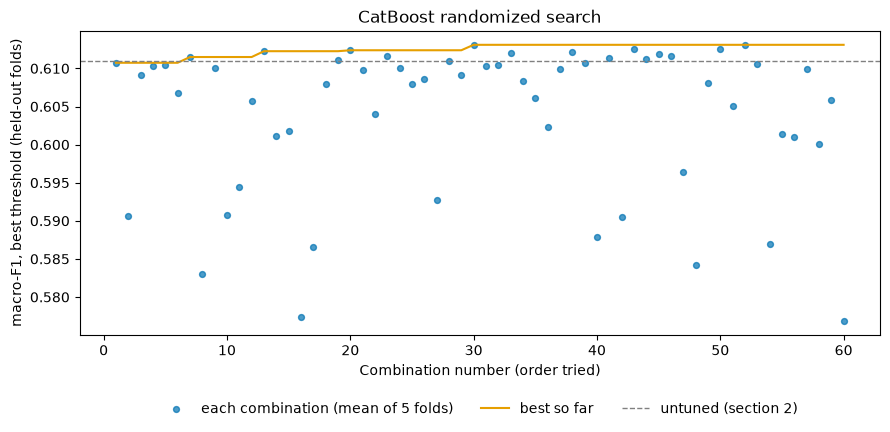

Best settings:
  bagging_temperature: 0.2265
  border_count: 254
  depth: 6
  iterations: 688
  l2_leaf_reg: 10.49
  learning_rate: 0.03726
  random_strength: 7.472


In [6]:
# Each combination's held-out macro-F1 (best threshold), in the order they were tried, and the best score so far
untuned_best_threshold_f1 = np.mean([best_threshold_macro_f1(y_train.iloc[valid_index], untuned_probabilities[valid_index])
                                     for _, valid_index in folds])

fig, ax = plt.subplots(figsize=(9, 4.5))
tried = results_df["mean_test_macro_f1_best_threshold"].to_numpy()
ax.scatter(np.arange(1, len(tried) + 1), tried, s=18, color="#0072B2", alpha=0.7, label="each combination (mean of 5 folds)")
ax.plot(np.arange(1, len(tried) + 1), np.maximum.accumulate(tried), color="#E69F00", label="best so far")
ax.axhline(untuned_best_threshold_f1, color="gray", ls="--", lw=1, label="untuned (section 2)")
ax.set_xlabel("Combination number (order tried)")
ax.set_ylabel("macro-F1, best threshold (held-out folds)")
ax.set_title("CatBoost randomized search")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

best_params = search.best_params_
print("Best settings:")
for name, value in best_params.items():
    print(f"  {name}: {value:.4g}" if isinstance(value, float) else f"  {name}: {value}")

### Reading the Search
- **The best combination reaches 0.613** macro-F1 at its best threshold, vs. 0.611 for the untuned model scored the same way (dashed line). The untuned CatBoost was already close to the best settings found.
- **The top combinations use fairly small trees (depth 3 to 7) and small learning rates (0.01 to 0.04) with many trees.** The best one: 688 trees, depth 6, learning rate 0.037, strong leaf penalty (`l2_leaf_reg` 10.5) and a lot of split randomness (`random_strength` 7.5).
- **Many settings score about the same.** The top 10 are all between 0.612 and 0.613, well within the fold-to-fold spread (about 0.007), so the exact "best" values shouldn't be over-interpreted.
- The top combinations also have high Disrupted PR-AUC (about 0.32-0.34), slightly above LightGBM's top 10 (0.31-0.33) and clearly above Random Forest's (about 0.29-0.30).

## 6. Tuned vs. Untuned
Get out-of-fold probabilities for the best settings (same folds), and compare with the untuned model **fold by fold**. Because both models are scored on exactly the same rows in each fold, the fold-by-fold difference shows whether the improvement is consistent or just noise.

The main comparison gives **each model its own Disrupted threshold**, chosen on the other 4 folds (the honest method from section 7), because that is how the final model will be used. The default-rule scores are shown too.

Note: the best settings were chosen using these same 5 folds, so the tuned score is slightly optimistic (it was the luckiest of 60 tries on these folds). The final test-set score in the comparison notebook will show the real number.

In [7]:
tuned_model = search.best_estimator_
tuned_probabilities = cross_val_predict(tuned_model, X_train, y_train, cv=folds, method="predict_proba")
tuned_fold_scores = score_folds(y_train, tuned_probabilities, folds)   # default rule

# Each model with its own threshold, chosen on the other 4 folds and scored on the held-out fold
untuned_threshold_scores = cross_validated_threshold(y_train, untuned_probabilities, folds).drop(columns="threshold")
tuned_threshold_fold_scores = cross_validated_threshold(y_train, tuned_probabilities, folds)
tuned_threshold_scores = tuned_threshold_fold_scores.drop(columns="threshold")

comparison = pd.DataFrame({
    "untuned, default rule": untuned_fold_scores.mean(),
    "tuned, default rule": tuned_fold_scores.mean(),
    "untuned, own threshold": untuned_threshold_scores.mean(),
    "tuned, own threshold": tuned_threshold_scores.mean(),
    "change with thresholds (mean)": (tuned_threshold_scores - untuned_threshold_scores).mean(),
    "change (std across folds)": (tuned_threshold_scores - untuned_threshold_scores).std(),
    "folds improved (of 5)": (tuned_threshold_scores > untuned_threshold_scores).sum(),
})
comparison.round(3)

,"untuned, default rule","tuned, default rule","untuned, own threshold","tuned, own threshold",change with thresholds (mean),change (std across folds),folds improved (of 5)
macro_f1,0.548,0.548,0.605,0.610,0.005,0.005,5
f1_normal,0.688,0.688,0.688,0.688,0.000,0.002,3
f1_delayed,0.681,0.683,0.767,0.770,0.003,0.004,4
f1_disrupted,0.274,0.271,0.361,0.372,0.011,0.012,5
disrupted_precision,0.170,0.168,0.325,0.340,0.014,0.023,4
disrupted_recall,0.717,0.707,0.408,0.412,0.004,0.028,2
disrupted_pr_auc,0.319,0.332,0.319,0.332,0.013,0.007,5
roc_auc_ovr,0.840,0.841,0.840,0.841,0.001,0.001,3


### Reading the Comparison
- **With their own thresholds, tuning improves macro-F1 by about 0.005 (0.605 -> 0.610), on all 5 folds**, and Disrupted PR-AUC by about 0.013 (0.319 -> 0.332), also on all 5 folds. Small, but consistent.
- With the default rule, tuned and untuned score the same (0.548): both flag many rows as Disrupted (recall about 0.71, precision about 0.17), which the threshold fixes.
- CatBoost was already strong untuned, so tuning adds only a little. Its advantage over the other algorithms is that it **ranks disruptions best** (highest PR-AUC).

## 7. Choose the Disrupted Threshold
As in 03, a row is called Disrupted when its Disrupted probability is at least a threshold; otherwise the more likely of Normal and Delayed is predicted. Thresholds from 0.05 to 0.95 in steps of 0.01 are tried.

**How the threshold is chosen:** the one with the **highest macro-F1**. This is the default until the team agrees on the cost of a missed disruption vs. a false alarm (see the recall-target table below for an alternative).

**How it is scored honestly:** a threshold chosen and scored on the same rows looks better than it really is. So, for each fold, the threshold is chosen on the **other 4 folds** and then scored on this fold, which it never saw (`cross_validated_threshold` in `tuning_setup.py`). The threshold saved for the final model is chosen on all training rows.

In [8]:
threshold_fold_scores = tuned_threshold_fold_scores   # from section 6
final_threshold = choose_threshold(y_train, tuned_probabilities)

threshold_comparison = pd.DataFrame({
    "default rule (mean)": tuned_fold_scores.mean(),
    "chosen threshold (mean)": threshold_fold_scores.drop(columns="threshold").mean(),
    "change (mean)": (threshold_fold_scores.drop(columns="threshold") - tuned_fold_scores).mean(),
    "folds improved (of 5)": (threshold_fold_scores.drop(columns="threshold") > tuned_fold_scores).sum(),
})
print("Threshold chosen in each fold (on the other 4 folds):", threshold_fold_scores["threshold"].tolist())
print("Final threshold (chosen on all training rows):", final_threshold)
threshold_comparison.round(3)

Threshold chosen in each fold (on the other 4 folds): [0.8, 0.79, 0.79, 0.79, 0.79]
Final threshold (chosen on all training rows): 0.79


,default rule (mean),chosen threshold (mean),change (mean),folds improved (of 5)
macro_f1,0.548,0.610,0.062,5
f1_normal,0.688,0.688,0.000,0
f1_delayed,0.683,0.770,0.086,5
f1_disrupted,0.271,0.372,0.101,5
disrupted_precision,0.168,0.340,0.172,5
disrupted_recall,0.707,0.412,-0.295,0
disrupted_pr_auc,0.332,0.332,0.000,0
roc_auc_ovr,0.841,0.841,0.000,0


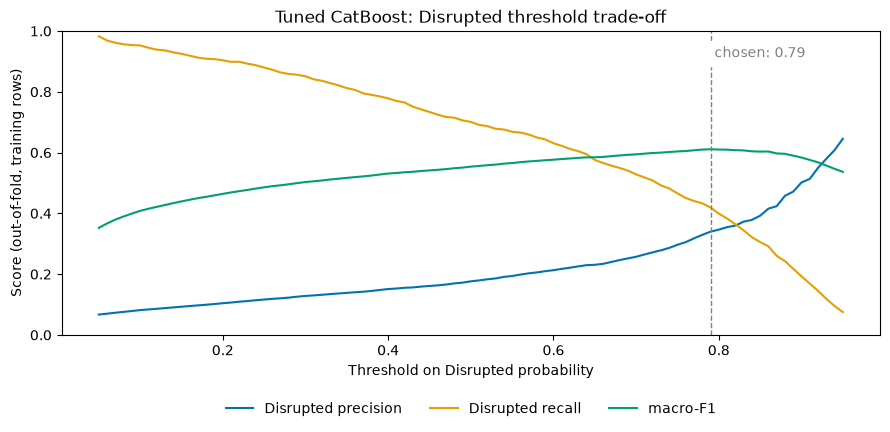

In [9]:
# The full trade-off for the tuned model (out-of-fold, all training rows)
trade_off = pd.DataFrame([
    {"threshold": t, **score_predictions(y_train, tuned_probabilities, t),
     "rows flagged Disrupted": int((predict_with_threshold(tuned_probabilities, t) == DISRUPTED).sum())}
    for t in THRESHOLDS
]).set_index("threshold")

fig, ax = plt.subplots(figsize=(9, 4.5))
for column, color, label in [("disrupted_precision", "#0072B2", "Disrupted precision"),
                             ("disrupted_recall", "#E69F00", "Disrupted recall"),
                             ("macro_f1", "#009E73", "macro-F1")]:
    ax.plot(trade_off.index, trade_off[column], color=color, label=label)
ax.axvline(final_threshold, color="gray", ls="--", lw=1)
ax.text(final_threshold, 0.95, f" chosen: {final_threshold}", color="gray", va="top", backgroundcolor="white")
ax.set_xlabel("Threshold on Disrupted probability")
ax.set_ylabel("Score (out-of-fold, training rows)")
ax.set_ylim(0, 1)
ax.set_title("Tuned CatBoost: Disrupted threshold trade-off")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### Alternative: a Recall Target
If the team decides that catching disruptions matters more than avoiding false alarms, a threshold can instead be chosen to reach a **recall target**: the highest threshold that still catches at least that share of real disruptions. The table shows what each target would cost in precision and false alarms.

In [10]:
recall_target_rows = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    meets_target = trade_off[trade_off["disrupted_recall"] >= target]
    if meets_target.empty:
        # Even the lowest threshold tried doesn't catch this share of disruptions
        recall_target_rows.append({"recall target": target, "threshold": "not reachable"})
        continue
    threshold = meets_target.index.max()
    row = trade_off.loc[threshold]
    caught = row["disrupted_recall"] * (y_train == DISRUPTED).sum()
    recall_target_rows.append({
        "recall target": target,
        "threshold": threshold,
        "disrupted_recall": row["disrupted_recall"],
        "disrupted_precision": row["disrupted_precision"],
        "macro_f1": row["macro_f1"],
        "false alarms per disruption caught": (row["rows flagged Disrupted"] - caught) / caught,
    })

pd.DataFrame(recall_target_rows).set_index("recall target").round(3)

,threshold,disrupted_recall,disrupted_precision,macro_f1,false alarms per disruption caught
recall target,,,,,
0.5,0.72,0.508,0.272,0.599,2.680
0.6,0.63,0.605,0.225,0.583,3.435
0.7,0.50,0.701,0.176,0.554,4.671
0.8,0.36,0.806,0.140,0.519,6.123
0.9,0.20,0.904,0.104,0.464,8.598


### Reading the Threshold Results
- **The chosen threshold improves macro-F1 by about 0.062 over the default rule, on all 5 folds.** The thresholds chosen in each fold are very stable (0.79 to 0.80), and the final threshold is **0.79**.
- Why so high: the class weights make the model's Disrupted probabilities much larger than the real chance of a disruption. A threshold around 0.8 undoes that push.
- The trade-off: Disrupted precision doubles (0.17 -> 0.34) but recall falls (0.71 -> 0.41).
- **Recall targets** (from the table): catching 50% of disruptions costs about 2.7 false alarms per disruption caught (threshold 0.72), 70% costs about 4.7 (0.50), and 90% about 8.6 (0.20).

## 8. Save the Results
Saved to `results/tuning/catboost/` in the shared format, so the comparison notebook can load every algorithm the same way:
- `best_params.json`: the best settings and the chosen Disrupted threshold
- `cv_fold_scores.csv`: the tuned model's scores on each fold, with the chosen threshold (from section 7, chosen on the other folds)
- `out_of_fold_probabilities.csv`: each training row's out-of-fold probabilities, with `date`, `route_id` and the true status
- `search_results.csv`: every combination tried in the search, best first

In [11]:
folder = save_tuning_results(
    model_name="CatBoost",
    best_params=best_params,
    fold_scores_df=threshold_fold_scores,
    out_of_fold_probabilities=tuned_probabilities,
    train_df=train_df,
    threshold=final_threshold,
    search_results_df=search_results_df,
)
print("Saved to", folder)

Saved to ../results/tuning\catboost


## 9. Summary
**Setup:** randomized search over 7 CatBoost settings (60 combinations), stratified 5-fold cross-validation on the training rows (same folds as 03), balanced class weights (same values as 03). Settings chosen by **macro-F1 at their best Disrupted threshold**. The test set was not used.

**Results (mean over the 5 folds; each model with its own threshold, chosen on the other 4 folds)**

| | macro-F1 | Disrupted F1 | Disrupted precision | Disrupted recall | Disrupted PR-AUC |
|---|---|---|---|---|---|
| Untuned (03 settings) | 0.605 | 0.361 | 0.325 | 0.408 | 0.319 |
| **Tuned** (threshold 0.79) | **0.610** | **0.372** | 0.340 | 0.412 | **0.332** |

**What we learned**
1. Tuning gives CatBoost a small but consistent gain (+0.005 macro-F1, +0.013 Disrupted PR-AUC, better on all 5 folds).
2. CatBoost has the best scores of the three tuned algorithms on both macro-F1 and Disrupted PR-AUC, although the gaps are small (about 0.01).
3. As for the other algorithms, a threshold around 0.8 is needed to undo the push the class weights give to Disrupted.

**Saved:** `results/tuning/catboost/` (best settings, threshold 0.79, fold scores, out-of-fold probabilities, all search results).

**Next steps**
- Compare the three tuned models (LightGBM, Random Forest, CatBoost) in one notebook, using the saved results in `results/tuning/`.
- Agree as a team on what the final model should optimize: macro-F1 (current default), or a recall target. The recall-target table shows what each target costs in false alarms.
- Score the chosen model **once** on the test set, and also report the score for test rows from 2026-06-07 onward.